# Autoregressive Next-Word Text Generation with Recurrent Neural Networks
### Foundations of Generative AI (ICT4403), Assignment 2

**System:** *FableForge*, a word-level autoregressive text generator trained on *Indian Fairy Tales*.

This notebook implements and compares four recurrent architectures (Simple RNN, Bidirectional RNN,
LSTM and GRU) trained under identical settings to predict the next word and to generate text one word
at a time from seed sequences at several sampling temperatures.

## 0. Configuration

In [1]:
import os, re, time, math, random, copy, json
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
%matplotlib inline

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))

# ---- shared experimental configuration (identical for all four models) ----
SEQ_LEN    = 10      # context window (words)
VOCAB_SIZE = 3000    # most frequent training words kept; remainder -> <unk>
EMB_DIM    = 64
HID_DIM    = 128
STRIDE     = 8       # sliding-window stride used to build sequences
EPOCHS     = 8
BATCH      = 512
LR         = 1e-3
TRAIN_FRAC = 0.80
VAL_FRAC   = 0.10    # remaining 0.10 is the test split

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| PyTorch', torch.__version__, '| threads', torch.get_num_threads())

Device: cpu | PyTorch 2.14.1+cpu | threads 2


## 1. Dataset

*Indian Fairy Tales*, compiled by Joseph Jacobs (Project Gutenberg eBook #7128), is a public-domain
collection of 29 Indian folk and fairy tales written in consistent English narrative prose, a good
fit for word-level language modelling. We download the plain-text edition and keep only the tale
narrative: the licence header/footer, the front matter and the scholarly *Notes and References*
appendix are removed so the corpus is stylistically uniform.

In [2]:
URL = 'https://www.gutenberg.org/cache/epub/7128/pg7128.txt'
DATA_DIR = 'data'; os.makedirs(DATA_DIR, exist_ok=True)
RAW_PATH = os.path.join(DATA_DIR, 'indian_fairy_tales_raw.txt')
if not os.path.exists(RAW_PATH):
    import urllib.request
    urllib.request.urlretrieve(URL, RAW_PATH)
raw = open(RAW_PATH, encoding='utf-8', errors='replace').read()
print('Raw characters:', len(raw))

Raw characters: 406540


In [3]:
def clean_corpus(text):
    """Keep only the tales: drop the Gutenberg licence header/footer, the front
    matter (preface / contents / illustration list) and the 'Notes and
    References' appendix at the end."""
    s = text.find('*** START OF THE PROJECT GUTENBERG')
    e = text.find('*** END OF THE PROJECT GUTENBERG')
    body = text[s:e] if (s != -1 and e != -1) else text
    start = body.find('The Lion and the Crane')       # first tale
    end = body.find('Notes and References', start)    # start of the appendix
    body = body[start:end]
    body = re.sub(r'\[Illustration:[^\]]*\]', ' ', body)
    body = re.sub(r'\[[^\]]{0,60}\]', ' ', body)
    return body

corpus = clean_corpus(raw)
tokens_all = re.findall(r"[a-z']+", corpus.lower())
print('Characters :', len(corpus))
print('Words      :', len(tokens_all))
print('Unique     :', len(set(tokens_all)))

Characters : 304759
Words      : 58104
Unique     : 4332


## 2. Preprocessing and input-target construction

The token stream is split **80 / 10 / 10** into contiguous train / validation / test segments, so that
no context window crosses a segment boundary. The vocabulary is built **from the training segment only**
(the 3,000 most frequent words); all other words map to `<unk>`, with index 0 reserved for `<pad>`.
Autoregressive input-target pairs are then built within each segment with a sliding window: a window of
`SEQ_LEN` consecutive words is the input and the following word is the target.

In [4]:
n = len(tokens_all)
ntr, nva = int(TRAIN_FRAC * n), int((TRAIN_FRAC + VAL_FRAC) * n)
tr_tokens, va_tokens, te_tokens = tokens_all[:ntr], tokens_all[ntr:nva], tokens_all[nva:]

# vocabulary from the TRAINING segment only
counts = Counter(tr_tokens)
vocab_words = [w for w, _ in counts.most_common(VOCAB_SIZE - 2)]
word2idx = {w: i + 2 for i, w in enumerate(vocab_words)}   # 0=<pad>, 1=<unk>
idx2word = {i: w for w, i in word2idx.items()}
idx2word[0] = '<pad>'; idx2word[1] = '<unk>'
VOCAB = len(idx2word)

def encode(toks): return [word2idx.get(t, 1) for t in toks]
tr_ids, va_ids, te_ids = encode(tr_tokens), encode(va_tokens), encode(te_tokens)

cov = 100 * sum(1 for t in tokens_all if t in word2idx) / len(tokens_all)
print('Vocabulary size (incl. <pad>, <unk>):', VOCAB)
print('Coverage of kept vocabulary over the whole corpus: %.1f%%' % cov)
print('Train / val / test tokens: %d / %d / %d' % (len(tr_ids), len(va_ids), len(te_ids)))

Vocabulary size (incl. <pad>, <unk>): 3000
Coverage of kept vocabulary over the whole corpus: 97.0%
Train / val / test tokens: 46483 / 5810 / 5811


In [5]:
def make_sequences(seq):
    X, y = [], []
    for i in range(0, len(seq) - SEQ_LEN, STRIDE):
        X.append(seq[i:i + SEQ_LEN]); y.append(seq[i + SEQ_LEN])
    return np.array(X, dtype='int64'), np.array(y, dtype='int64')

Xtr, ytr = make_sequences(tr_ids)
Xval, yval = make_sequences(va_ids)
Xte, yte = make_sequences(te_ids)
print('Train sequences :', Xtr.shape, '->', len(Xtr), 'next-word targets')
print('Val sequences   :', Xval.shape, '->', len(Xval), 'next-word targets')
print('Test sequences  :', Xte.shape, '->', len(Xte), 'next-word targets')

Train sequences : (5810, 10) -> 5810 next-word targets
Val sequences   : (725, 10) -> 725 next-word targets
Test sequences  : (726, 10) -> 726 next-word targets


## 3. Models

Every model shares the same interface (embedding, recurrent layer and dense softmax head), so the
comparison is like-for-like; only the recurrent layer changes.

| Model | Recurrent layer | Direction |
|---|---|---|
| SimpleRNN | `nn.RNN` | unidirectional |
| BiRNN | `nn.RNN` | bidirectional |
| LSTM | `nn.LSTM` | unidirectional |
| GRU | `nn.GRU` | unidirectional |

> **Note on the Bidirectional RNN.** A bidirectional layer reads its input window in both directions, so
> when it predicts the next word it can use *future* words within that window. The next-word task is
> therefore non-causal for the BiRNN, and a truly autoregressive generator cannot use it. It is included
> as required and this caveat is carried into the discussion.

In [6]:
RNN_MAP = {'SimpleRNN': (nn.RNN, False),
           'BiRNN':     (nn.RNN, True),
           'LSTM':      (nn.LSTM, False),
           'GRU':       (nn.GRU, False)}

class NextWordModel(nn.Module):
    def __init__(self, kind, vocab=VOCAB, emb=EMB_DIM, hid=HID_DIM):
        super().__init__()
        cls, bi = RNN_MAP[kind]
        self.emb = nn.Embedding(vocab, emb)
        self.rnn = cls(emb, hid, batch_first=True, bidirectional=bi)
        self.drop = nn.Dropout(0.2)
        self.fc = nn.Linear(hid * (2 if bi else 1), vocab)

    def forward(self, x):
        h, _ = self.rnn(self.emb(x))
        return self.fc(self.drop(h[:, -1]))

def n_params(m): return sum(p.numel() for p in m.parameters())

In [7]:
def evaluate(model, X, y):
    """Return (loss, top-1 accuracy, top-5 accuracy, n) on a split."""
    model.eval()
    X_t = torch.tensor(X).to(DEVICE); y_t = torch.tensor(y).to(DEVICE)
    lossf = nn.CrossEntropyLoss()
    tot = 0.0; top1 = 0; top5 = 0; n = 0
    with torch.no_grad():
        for i in range(0, len(X_t), 2048):
            xb = X_t[i:i + 2048]; yb = y_t[i:i + 2048]
            out = model(xb)
            tot += lossf(out, yb).item() * len(xb)
            k = min(5, out.size(1))
            _, topk = out.topk(k, dim=1)
            top1 += (topk[:, 0] == yb).sum().item()
            top5 += (topk == yb.unsqueeze(1)).any(1).sum().item()
            n += len(xb)
    return tot / n, top1 / n, top5 / n, n

def train_model(kind, epochs=EPOCHS, bs=BATCH, lr=LR, verbose=True):
    """Train one model; keep the best checkpoint by validation loss."""
    torch.manual_seed(SEED)
    model = NextWordModel(kind).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.CrossEntropyLoss()
    Xtr_t, ytr_t = torch.tensor(Xtr), torch.tensor(ytr)

    hist = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    best_val, best_state = float('inf'), None
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tot = 0.0; nb = 0
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(Xtr_t), bs):
            idxb = perm[i:i + bs]
            xb = Xtr_t[idxb].to(DEVICE); yb = ytr_t[idxb].to(DEVICE)
            opt.zero_grad()
            loss = lossf(model(xb), yb)
            loss.backward(); opt.step()
            tot += loss.item(); nb += 1
        tr_loss = tot / nb
        val_loss, val_acc, _, _ = evaluate(model, Xval, yval)
        hist['train_loss'].append(tr_loss)
        hist['val_loss'].append(val_loss)
        hist['val_acc'].append(val_acc)
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f'  epoch {ep:2d}/{epochs}  train_loss={tr_loss:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}')
    model.load_state_dict(best_state)          # restore best checkpoint
    return model, hist, time.time() - t0, best_val

In [8]:
models, results = {}, {}
for kind in ['SimpleRNN', 'BiRNN', 'LSTM', 'GRU']:
    print(f'=== Training {kind} ===')
    m, h, t, bv = train_model(kind)
    models[kind] = m
    results[kind] = {'history': h, 'time': t, 'best_val_loss': bv, 'params': n_params(m)}
    print(f'  -> best val loss {bv:.4f} | training time {t:.1f}s | {n_params(m):,} params\n')

=== Training SimpleRNN ===


  epoch  1/8  train_loss=7.9607  val_loss=7.7553  val_acc=0.0152


  epoch  2/8  train_loss=7.1183  val_loss=6.3263  val_acc=0.0262


  epoch  3/8  train_loss=6.0977  val_loss=5.8741  val_acc=0.0745


  epoch  4/8  train_loss=5.9028  val_loss=5.9057  val_acc=0.0759


...

  epoch  4/8  train_loss=5.9102  val_loss=5.9261  val_acc=0.0759


  epoch  5/8  train_loss=5.8428  val_loss=5.9365  val_acc=0.0772


  epoch  6/8  train_loss=5.7942  val_loss=5.9058  val_acc=0.0800


  epoch  7/8  train_loss=5.7578  val_loss=5.8967  val_acc=0.0786


  epoch  8/8  train_loss=5.7125  val_loss=5.8906  val_acc=0.0855
  -> best val loss 5.8906 | training time 33.8s | 653,496 params



## 4. Evaluation on the test split

Each model is evaluated once on the held-out **test** split (loss, perplexity, top-1 and top-5
next-word accuracy). A context-free **unigram baseline** (always predict the most frequent training
word, with its training-set probability) is included as a reference point.

In [9]:
# ---- unigram baseline built from the TRAINING segment ----
tot_tr = sum(counts.values())
uni = np.array([counts.get(idx2word[i], 0) / tot_tr for i in range(VOCAB)])
uni = np.clip(uni, 1e-12, None); uni = uni / uni.sum()
bl_loss = -np.mean(np.log(uni[yte]))
bl_ppl = math.exp(bl_loss)
bl_top1 = float(np.mean(uni.argmax() == yte))

rows = []
for k in models:
    loss, t1, t5, n = evaluate(models[k], Xte, yte)
    rows.append((k, loss, math.exp(loss), t1, t5, results[k]['params'], results[k]['time']))

print(f"{'Model':<12}{'Loss':>9}{'Perplexity':>12}{'Top-1':>9}{'Top-5':>9}{'Params':>12}{'Train time':>12}")
print('-' * 75)
for k, loss, ppl, t1, t5, p, t in rows:
    print(f"{k:<12}{loss:>9.4f}{ppl:>12.2f}{t1*100:>8.2f}%{t5*100:>8.2f}%{p:>12,}{t:>10.0f} s")
print(f"{'Unigram':<12}{bl_loss:>9.4f}{bl_ppl:>12.2f}{bl_top1*100:>8.2f}%{'-':>9}{'-':>12}{'-':>12}")

test_results = {k: {'loss': loss, 'ppl': ppl, 'top1': t1, 'top5': t5, 'params': p, 'time': t}
                for (k, loss, ppl, t1, t5, p, t) in rows}
test_results['Unigram'] = {'loss': bl_loss, 'ppl': bl_ppl, 'top1': bl_top1, 'top5': None,
                           'params': None, 'time': None}
print('\nTest targets:', len(yte))

Model            Loss  Perplexity    Top-1    Top-5      Params  Train time
---------------------------------------------------------------------------
SimpleRNN      5.7572      316.47    7.58%   21.07%     603,832        20 s
BiRNN          5.6019      270.94   10.88%   28.51%   1,012,664        33 s
LSTM           5.7961      329.02    7.58%   19.01%     678,328        43 s
GRU            5.7851      325.41    8.40%   26.03%     653,496        34 s
Unigram        7.9022     2703.23    7.58%        -           -           -

Test targets: 726


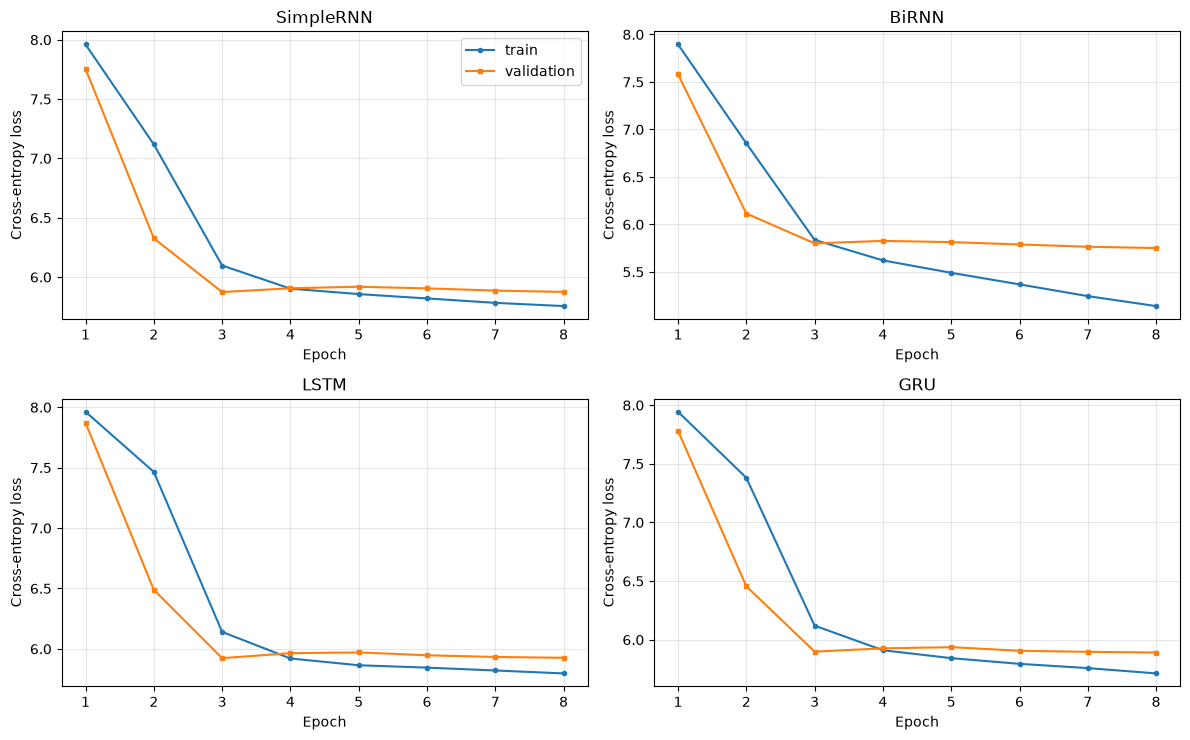

In [10]:
os.makedirs('figures', exist_ok=True)
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, k in zip(axes.ravel(), ['SimpleRNN', 'BiRNN', 'LSTM', 'GRU']):
    ep = range(1, EPOCHS + 1)
    ax.plot(ep, results[k]['history']['train_loss'], marker='o', ms=3, label='train')
    ax.plot(ep, results[k]['history']['val_loss'], marker='s', ms=3, label='validation')
    ax.set_title(k); ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-entropy loss'); ax.grid(alpha=0.3)
axes[0, 0].legend()
plt.tight_layout()
plt.savefig('figures/loss_curves.png', dpi=130, bbox_inches='tight'); plt.show()

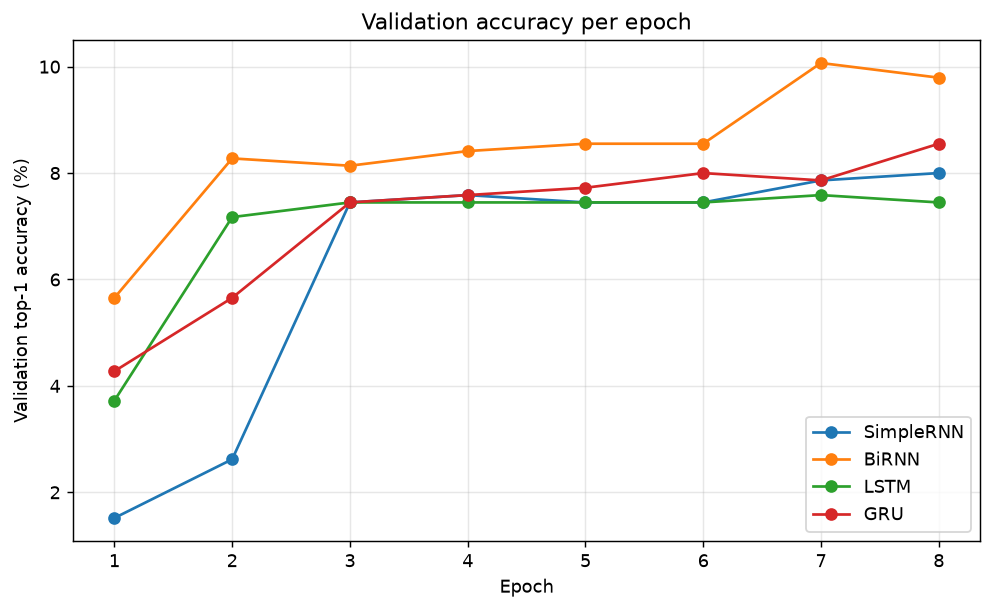

In [11]:
plt.figure(figsize=(9, 5))
for k in ['SimpleRNN', 'BiRNN', 'LSTM', 'GRU']:
    plt.plot(range(1, EPOCHS + 1), [a * 100 for a in results[k]['history']['val_acc']], marker='o', label=k)
plt.xlabel('Epoch'); plt.ylabel('Validation top-1 accuracy (%)')
plt.title('Validation accuracy per epoch'); plt.legend(); plt.grid(alpha=0.3)
plt.savefig('figures/accuracy_curves.png', dpi=130, bbox_inches='tight'); plt.show()

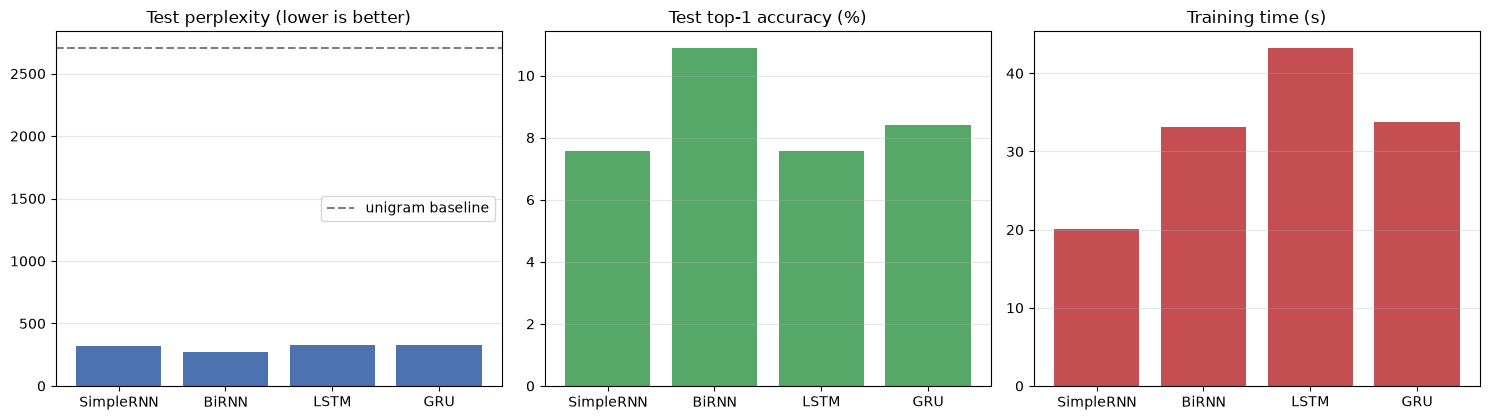

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ks = ['SimpleRNN', 'BiRNN', 'LSTM', 'GRU']
axes[0].bar(ks, [test_results[k]['ppl'] for k in ks], color='#4C72B0')
axes[0].axhline(bl_ppl, color='grey', ls='--', label='unigram baseline')
axes[0].set_title('Test perplexity (lower is better)'); axes[0].legend()
axes[1].bar(ks, [test_results[k]['top1'] * 100 for k in ks], color='#55A868')
axes[1].set_title('Test top-1 accuracy (%)')
axes[2].bar(ks, [results[k]['time'] for k in ks], color='#C44E52')
axes[2].set_title('Training time (s)')
for ax in axes: ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('figures/model_comparison.png', dpi=130, bbox_inches='tight'); plt.show()

## 5. Autoregressive generation and sampling temperature

Text is generated one word at a time. The next-word softmax distribution is divided by a **temperature**
`T` before sampling (`T < 1` sharpens, which is more coherent and more repetitive; `T > 1` flattens, which is more diverse
and less coherent). For every model we draw **nine continuations per temperature** (three fixed seed
sequences × three stochastic draws) and average three metrics over them:

* **distinct-2**: unique bigrams ÷ total bigrams (lexical diversity);
* **repeated-trigram rate**: 1 minus distinct-3 (phrase repetition);
* **`<unk>` rate**: fraction of generated tokens that are the unknown token.

An optional **top-k** filter is also applied for comparison.

In [13]:
def generate(model, seed, n_words=35, temp=1.0, top_k=None, seq_len=SEQ_LEN):
    model.eval()
    out = list(seed.split())
    ids = [word2idx.get(w, 1) for w in out][-seq_len:]
    with torch.no_grad():
        for _ in range(n_words):
            x = torch.tensor([ids[-seq_len:]], dtype=torch.long).to(DEVICE)
            logits = model(x)[0] / temp
            if top_k:
                v, _ = torch.topk(logits, top_k)
                logits = torch.where(logits < v[-1], torch.full_like(logits, float('-inf')), logits)
            probs = torch.softmax(logits, dim=-1).cpu().numpy()
            nxt = int(np.random.choice(len(probs), p=probs))
            ids.append(nxt); out.append(idx2word[nxt])
    return ' '.join(out)

def cont_metrics(text):
    ws = text.split()
    def distinct(nn_):
        g = [tuple(ws[i:i + nn_]) for i in range(len(ws) - nn_ + 1)]
        return len(set(g)) / len(g) if g else 0.0
    unk = sum(1 for w in ws if w == '<unk>') / len(ws)
    return distinct(2), 1 - distinct(3), unk

SEEDS = ['the king said to', 'there lived a', 'the lion and the']
TEMPS = [0.5, 1.0, 1.5]

def sample_metrics(model, temp, top_k=None, reps=3, n_words=35):
    d2, r3, uk = [], [], []
    texts = []
    for s in SEEDS:
        for _ in range(reps):
            txt = generate(model, s, n_words=n_words, temp=temp, top_k=top_k)
            texts.append(txt)
            a, b, c = cont_metrics(txt); d2.append(a); r3.append(b); uk.append(c)
    return {'distinct2': float(np.mean(d2)), 'rep_trigram': float(np.mean(r3)),
            'unk_rate': float(np.mean(uk))}, texts

raw_metrics, samples = {}, {}
for k in models:
    raw_metrics[k] = {}
    for T in TEMPS:
        m_, texts = sample_metrics(models[k], T)
        raw_metrics[k][T] = m_
        samples.setdefault(k, {})[T] = texts[0]        # keep one representative sample

print('Raw sampling, mean over 9 continuations per temperature\n')
print(f"{'Model':<11}" + ''.join(f"{'T='+str(T):>26}" for T in TEMPS))
print(f"{'':11}" + ''.join(f"{'dist2':>9}{'rep3':>9}{'unk':>8}" for T in TEMPS))
for k in models:
    line = f"{k:<11}"
    for T in TEMPS:
        m_ = raw_metrics[k][T]
        line += f"{m_['distinct2']:>9.3f}{m_['rep_trigram']:>9.3f}{m_['unk_rate']:>8.3f}"
    print(line)

Raw sampling, mean over 9 continuations per temperature

Model                           T=0.5                     T=1.0                     T=1.5
               dist2     rep3     unk    dist2     rep3     unk    dist2     rep3     unk
SimpleRNN      0.678    0.118   0.029    0.997    0.000   0.014    1.000    0.000   0.003
BiRNN          0.817    0.064   0.017    0.997    0.000   0.017    1.000    0.000   0.000
LSTM           0.646    0.134   0.009    0.994    0.000   0.020    1.000    0.000   0.014
GRU            0.850    0.024   0.031    1.000    0.000   0.017    1.000    0.000   0.003


In [14]:
# representative raw samples (T = 0.5 / 1.0 / 1.5), seed "the king said to"
for k in models:
    print('=' * 72); print('MODEL:', k)
    for T in TEMPS:
        print(f'  T={T}: {samples[k][T]}')
    print()

MODEL: SimpleRNN
  T=0.5: the king said to the me he to the the the was to he <unk> very in the the the the and and the to the the the and a the and and the to the the my very
  T=1.0: the king said to gangazara at to to his which hand saying in former hands see only but his she fear <unk> and the the none replied them and have prince to when as only has the with down
  T=1.5: the king said to wait gates matter sure him returned most if which king's the can them after it already happily fond livelihood fire you yet plain touch still said how last neither followed has skilled agreed now i

MODEL: BiRNN
  T=0.5: the king said to <unk> the whole they of the young and then and and he <unk> the tiger the young to and the king of the raja and i am and the in the young and he was
  T=1.0: the king said to her turn had by <unk> the tiger them could him husband dip world and will he she busy he let out here she <unk> of me the down the they so and if ring wicked
  T=1.5: the king said to him th

In [15]:
# top-k filtered sampling (k = 50) for comparison with raw sampling
topk_metrics = {}
for k in models:
    topk_metrics[k] = {T: sample_metrics(models[k], T, top_k=50, reps=2)[0] for T in TEMPS}

print('Repeated-trigram rate, raw vs top-k (k=50)\n')
print(f"{'Model':<11}" + ''.join(f"{'T='+str(T):>18}" for T in TEMPS))
print(f"{'':11}" + ''.join(f"{'raw':>9}{'topk':>9}" for T in TEMPS))
for k in models:
    line = f"{k:<11}"
    for T in TEMPS:
        line += f"{raw_metrics[k][T]['rep_trigram']:>9.3f}{topk_metrics[k][T]['rep_trigram']:>9.3f}"
    print(line)

Repeated-trigram rate, raw vs top-k (k=50)

Model                   T=0.5             T=1.0             T=1.5
                 raw     topk      raw     topk      raw     topk
SimpleRNN      0.118    0.114    0.000    0.000    0.000    0.000
BiRNN          0.064    0.133    0.000    0.000    0.000    0.000
LSTM           0.134    0.196    0.000    0.000    0.000    0.000
GRU            0.024    0.032    0.000    0.000    0.000    0.000


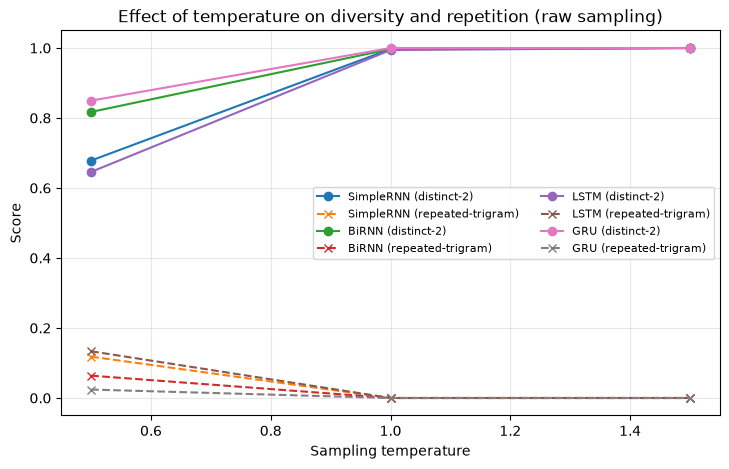

In [16]:
plt.figure(figsize=(8.5, 5))
for k in models:
    plt.plot(TEMPS, [raw_metrics[k][T]['distinct2'] for T in TEMPS], marker='o', label=f'{k} (distinct-2)')
    plt.plot(TEMPS, [raw_metrics[k][T]['rep_trigram'] for T in TEMPS], marker='x', ls='--',
             label=f'{k} (repeated-trigram)')
plt.xlabel('Sampling temperature'); plt.ylabel('Score')
plt.title('Effect of temperature on diversity and repetition (raw sampling)')
plt.legend(fontsize=8, ncol=2); plt.grid(alpha=0.3)
plt.savefig('figures/temperature_diversity.png', dpi=130, bbox_inches='tight'); plt.show()

## 6. Saving results

In [17]:
os.makedirs('models', exist_ok=True)
for k, m in models.items():
    torch.save(m.state_dict(), f'models/{k}.pt')

summary = {k: {'best_val_loss': results[k]['best_val_loss'],
               'test_loss': test_results[k]['loss'],
               'test_ppl': test_results[k]['ppl'],
               'test_top1': test_results[k]['top1'],
               'test_top5': test_results[k]['top5'],
               'params': results[k]['params'],
               'train_time_s': results[k]['time'],
               'history': results[k]['history']} for k in models}
out = {'config': {'seq_len': SEQ_LEN, 'vocab_size': VOCAB, 'emb_dim': EMB_DIM, 'hid_dim': HID_DIM,
                  'stride': STRIDE, 'epochs': EPOCHS, 'batch': BATCH, 'lr': LR,
                  'train_frac': TRAIN_FRAC, 'val_frac': VAL_FRAC},
       'test_targets': int(len(yte)),
       'baseline': {'loss': float(bl_loss), 'ppl': float(bl_ppl), 'top1': float(bl_top1)},
       'summary': summary,
       'temperature_raw': {k: {str(T): raw_metrics[k][T] for T in TEMPS} for k in models},
       'temperature_topk': {k: {str(T): topk_metrics[k][T] for T in TEMPS} for k in models},
       'samples': {k: {str(T): samples[k][T] for T in TEMPS} for k in models}}
json.dump(out, open('results.json', 'w'), indent=2)
print('Saved models/, figures/ and results.json')

Saved models/, figures/ and results.json


## 7. Conclusion

The results above identify the best-performing model for this dataset. Gated units (LSTM, GRU) are
expected to retain information across the context window better than the plain RNN, while the
Bidirectional RNN benefits from reading both directions but is not causal for generation. Sampling
temperature trades coherence against diversity in the expected way. See `README.md` for the full
discussion and the report for the final recommendation.